In [2]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns 
import pandas as pd 


In [3]:
df=pd.read_csv('../data/Complete_Dataset_updated.csv')

In [4]:
# frequency:

#for rained days vs didnot rain : 
didnot_rain=( df['Rainfall'] == 0 ).sum()
didnotraintotal=didnot_rain/len(df) * 100
print(didnotraintotal)

# for animals if they where took from filed or not : 
samples_from_field =(df['Animals'] == 1).sum()
print(samples_from_field)
samples_notFrom_filed = (df['Animals']==0 ).sum()
print(samples_notFrom_filed)

#for the sample type 
eachSampleType=df['Sample_type'].value_counts()
print(eachSampleType) # i will do bar chart for this 
#valuecounts counting accourance for each unique type , returning a series 
#sum just count all the coulmn , returing a number.

55.769230769230774
228
84
Sample_type
Q1    42
Q4    42
Q3    42
S1    42
S2    42
Q2    40
G1    20
G2    18
G3    12
G4    12
Name: count, dtype: int64


In [5]:
#mean for some features ( central tendency ): 
#ALL ARE INDICATING THE TYPICAL NUMBER IN THE COLUMN 

mean_biomass = df['Biomass'].mean()
print("mean_biomass :", mean_biomass)

mean_rainfall = df['Rainfall'].mean()
print("mean_rainfall :", mean_rainfall)

mean_temperature = df['TEMP_MAX'].mean()
print("mean_MAXtemperature : ", mean_temperature)

mean_temperature2 = df['TEMP_MIN'].mean()
print("mean_MINtemperature :",  mean_temperature2)

mean_wind_spd = df['WIND_SPD'].mean()
print("mean_wind_spd :",  mean_wind_spd)


mean_biomass : 4302.398076956089
mean_rainfall : 1.2910256410256409
mean_MAXtemperature :  31.096794871794874
mean_MINtemperature : 20.689743589743593
mean_wind_spd : 14.955769230769233


In [6]:
# Median for same features ( central tendency ) :

median_biomass=df['Biomass'].median()
print("median_biomass:" ,median_biomass)
# IT IS LESS THAN THE MEAN , THAT MEAN THAT THE DATA IS RIGHTLY MORE CLUSTRED FROM THE MEAN  

meadian_rainfall=df['Rainfall'].median()
print("median rainfall : " , meadian_rainfall)
# THE DIFFRENCE BETWEEN THE MEAN AND MEADIAN OF THIS INDICATES THAT THE MOST DAYS IRT DOESNT RAIN , WHILE WHEN IT RAIN IT IS HEAVY ( HIGHER MEAN ) EAVEN OF THIS IS NOT HAPPNING ALWAYS.

median_temperature_max = df['TEMP_MAX'].median()
print("median_MAXtemperature:", median_temperature_max)

median_temperature_min = df['TEMP_MIN'].median()
print("median_MINtemperature:", median_temperature_min)

median_wind_spd = df['WIND_SPD'].median()
print("median_wind_spd:", median_wind_spd)
# IT IS LESS THAN THE MEAN , THAT MEAN THAT THE DATA IS RIGHTLY MORE CLUSTRED FROM THE MEAN  


median_biomass: 3189.8333334999998
median rainfall :  0.0
median_MAXtemperature: 31.3
median_MINtemperature: 21.2
median_wind_spd: 14.5


In [7]:
# standered vediation for them ( Despresion ) I:

std_biomass=df['Biomass'].std()
print("std biomass : " , std_biomass)
#RESULT IS HIGH THIS MEANS WIDE DIVERSITY 

std_rainfall = df['Rainfall'].std()
print("std_rainfall:", std_rainfall)
#THE RESULT IS HIGH COMPARED TO THE MEAN, WHILE MOST DAYS DIDNOT RAIN AS SOWN IN THE FREQUENCY, BUT IT IS HIGH MENANING THAT WHEN IT RANS , THE RAIN IS HEAVY.

std_temperature_max = df['TEMP_MAX'].std()
print("std_temperature_max:", std_temperature_max)

std_temperature_min = df['TEMP_MIN'].std()
print("std_temperature_min:", std_temperature_min)

std_wind_spd = df['WIND_SPD'].std()
print("std_wind_spd:", std_wind_spd)
#RESULT NEAR TO THE MEAN AND median shows CONSISTANCY 

std biomass :  3279.9887257008513
std_rainfall: 3.5644614515877278
std_temperature_max: 1.9907961816536617
std_temperature_min: 2.5651681024543893
std_wind_spd: 3.7927031038606405


In [8]:
# IQR for features ( Descrision ):

Q1ofBiomass =df['Biomass'].quantile(0.25)
Q3ofBiomass =df['Biomass'].quantile(0.75)
iqr_biomass = Q3ofBiomass - Q1ofBiomass
print("IQR of Biomass:", iqr_biomass)
#very high IQR compared to other IQr's 

Q1ofRainfall = df['Rainfall'].quantile(0.25)
Q3ofRainfall = df['Rainfall'].quantile(0.75)
iqr_rainfall = Q3ofRainfall - Q1ofRainfall
print("IQR of Rainfall:", iqr_rainfall)
#low indicating that the middle 50% of data are close.

Q1ofTempMax = df['TEMP_MAX'].quantile(0.25)
Q3ofTempMax = df['TEMP_MAX'].quantile(0.75)
iqr_temp_max = Q3ofTempMax - Q1ofTempMax
print("IQR of Maximum Temperature:", iqr_temp_max)
#when this resulted in 1.6 and the in in 4.4 , this means that thier is wider variability in min temp. 

Q1ofTempMin = df['TEMP_MIN'].quantile(0.25)
Q3ofTempMin = df['TEMP_MIN'].quantile(0.75)
iqr_temp_min = Q3ofTempMin - Q1ofTempMin
print("IQR of Minimum Temperature:", iqr_temp_min)

Q1ofWindSpd = df['WIND_SPD'].quantile(0.25)
Q3ofWindSpd = df['WIND_SPD'].quantile(0.75)
iqr_wind_spd = Q3ofWindSpd - Q1ofWindSpd
print("IQR of Wind Speed:", iqr_wind_spd)

IQR of Biomass: 3210.916667
IQR of Rainfall: 0.8
IQR of Maximum Temperature: 1.6000000000000014
IQR of Minimum Temperature: 4.399999999999999
IQR of Wind Speed: 4.424999999999999


In [9]:
#Z score ( despriosn ) :

#biomass:
df['Biomass z-score'] = (df['Biomass'] - mean_biomass) / std_biomass 
z_score_range_value = df['Biomass z-score'].max() - df['Biomass z-score'].min() # what is the range of it - to understand the spread interms of the std- ?
print("range of Z-scores:", z_score_range_value)

# detict outliers:
df['Biomass outlier_zscore'] = (df['Biomass z-score'] > 3) | (df['Biomass z-score'] < -3 )
outliers_zscore_biomass = df[df['Biomass outlier_zscore'] == True]
print("Outliers based on Z-score in Biomass:", outliers_zscore_biomass)

#

range of Z-scores: 4.673430699071876
Outliers based on Z-score in Biomass:          Date  DOY  Sample  Sub-Sample        Lat      Long_ Sample_type  \
62   6/2/2022  153      32           1 -20.446996 -54.839329          S2   
63   6/2/2022  153      32           2 -20.446996 -54.839329          S2   
308  3/1/2023   60     155           1 -20.446937 -54.839311          S1   
309  3/1/2023   60     155           2 -20.446937 -54.839311          S1   

     Animals         DM        MM  ...  TP_SFC_AVG    Wind_Dir  Dew_Point  \
62         0  38.685941  6.693368  ...   21.054723  237.368612  19.593750   
63         0  38.873697  7.136434  ...   21.054723  237.368612  19.593750   
308        0  45.505167  8.263333  ...   19.443586  124.981135  12.442361   
309        0  45.493257  8.218142  ...   19.443586  124.981135  12.442361   

     Radiative_Dif_AVG  Radiative_Direct_AVG        PPFD  Longwave_Rad_AVG  \
62            99.04042             10.858880  216.264717        388.327589   
63

In [10]:
# position : 

# Decile : 
deciles = np.percentile(df['Biomass'], np.arange(10, 100, 10))# ARANGE IS FOR : FROM 10 TO 100 10 PART 
# THIS RESULT IN A LIST OF THE DECILES . 
print(deciles)
#results : 10% of data is under the first , 90% is under the last....
#this shows how the biomass values are fistiputed.
#look at the last 2 results: the diffrence bteen them indicates that the 10% last data are higher than others. 

[1520.333333  1800.5333336 2258.        2740.7333334 3189.8333335
 3687.        4721.4666668 5858.        9576.8000003]


In [11]:
# position : 

# Quartile : 
quartiles = df['Biomass'].quantile([0.25, 0.5, 0.75])
print("25th Quartile: ", quartiles[0.25])
print("50th Quartile: ", quartiles[0.5])#
print("75th Quartile: ", quartiles[0.75])

25th Quartile:  2026.333333
50th Quartile:  3189.8333334999998
75th Quartile:  5237.25


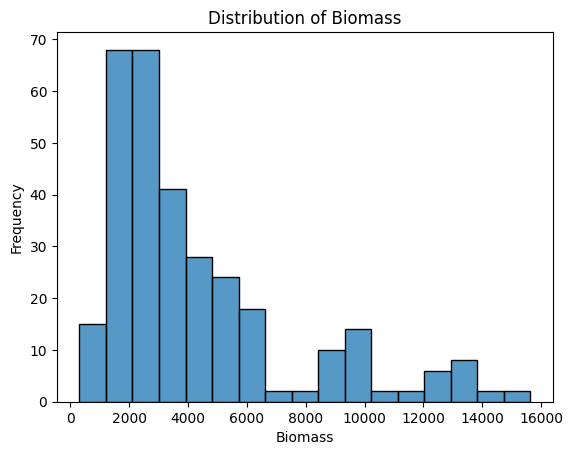

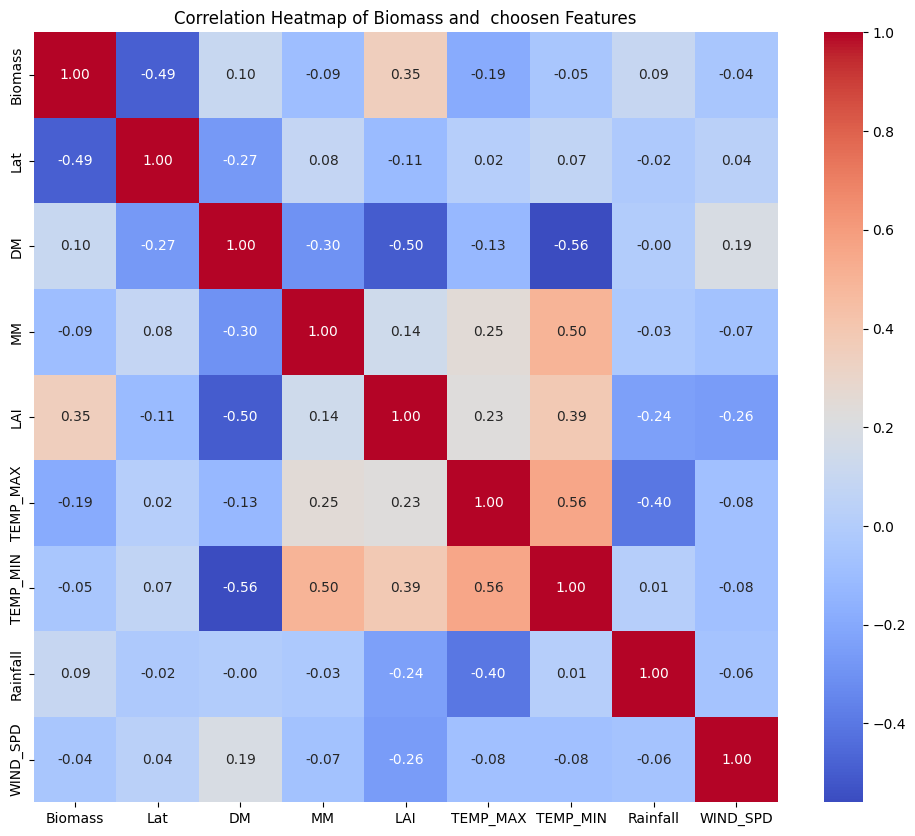

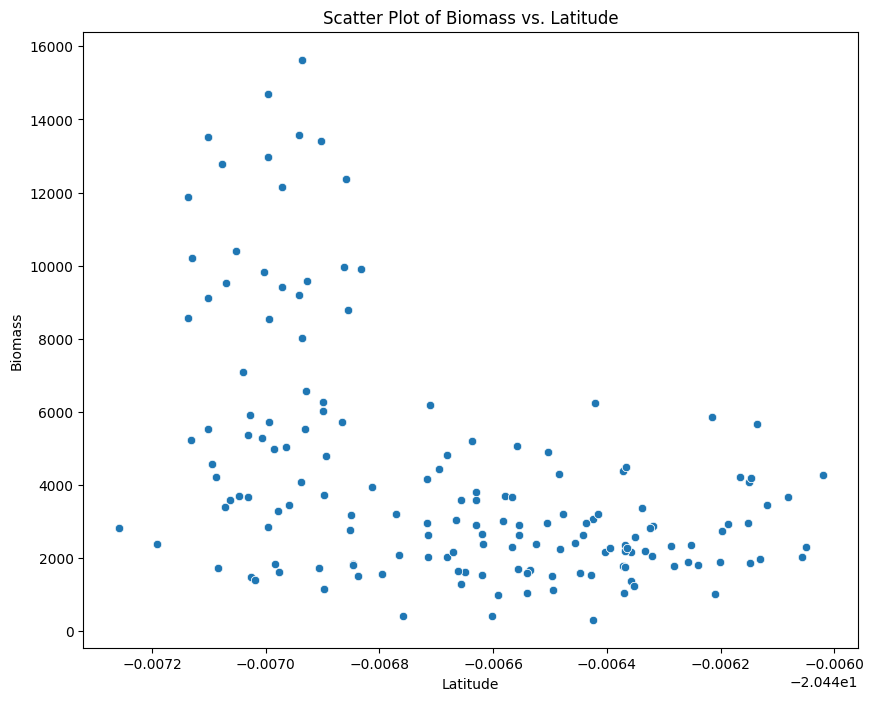

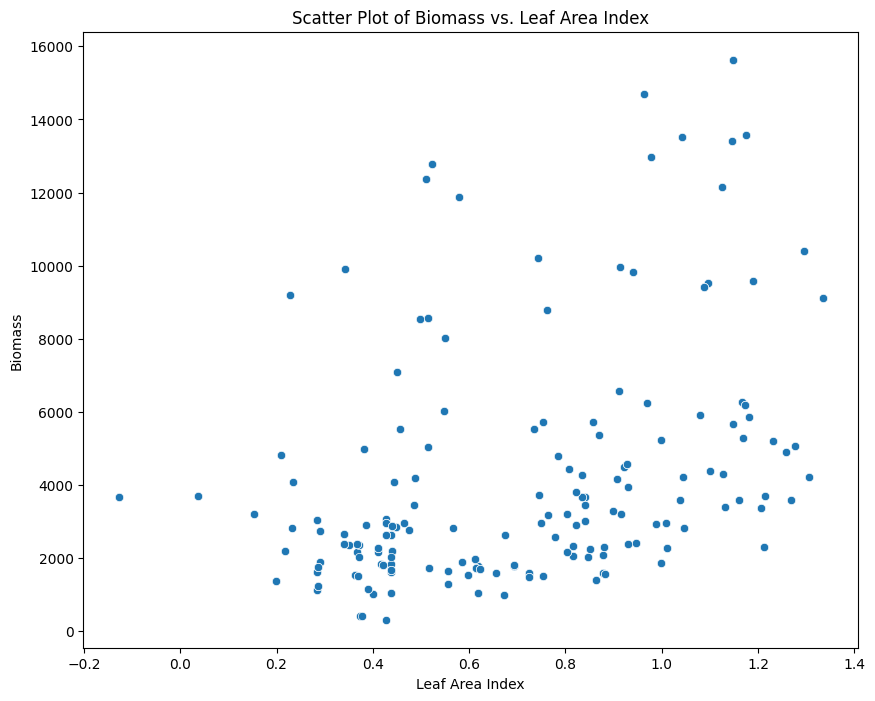

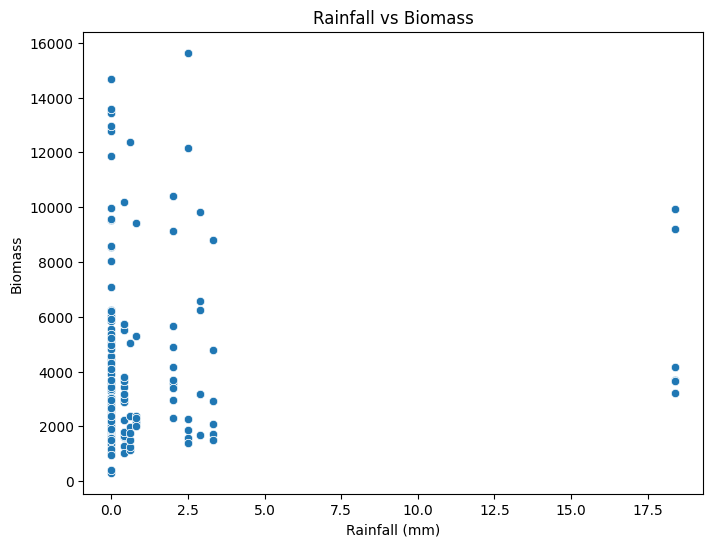

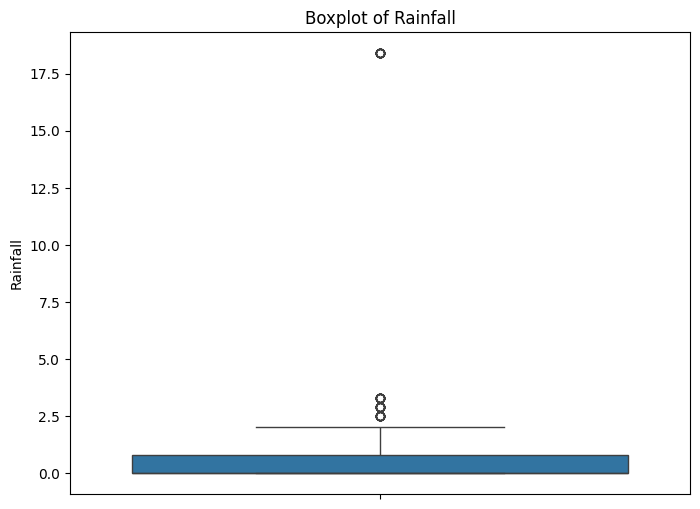

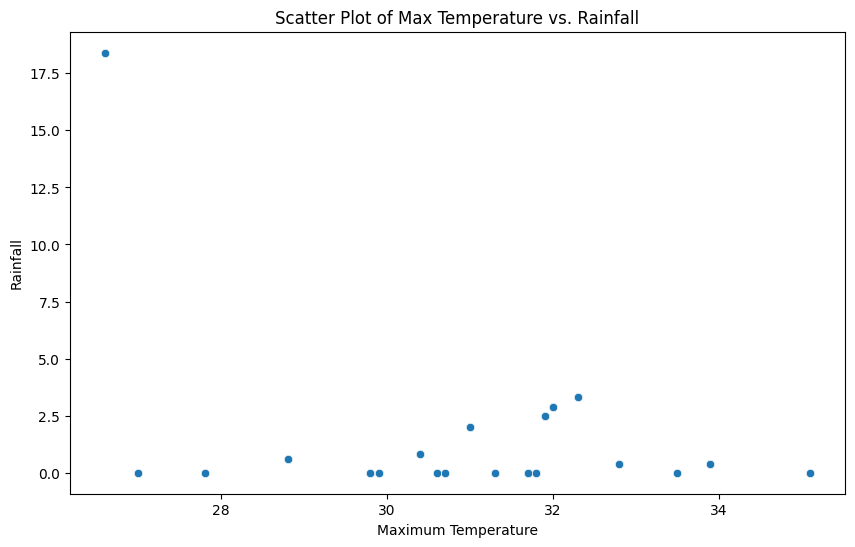

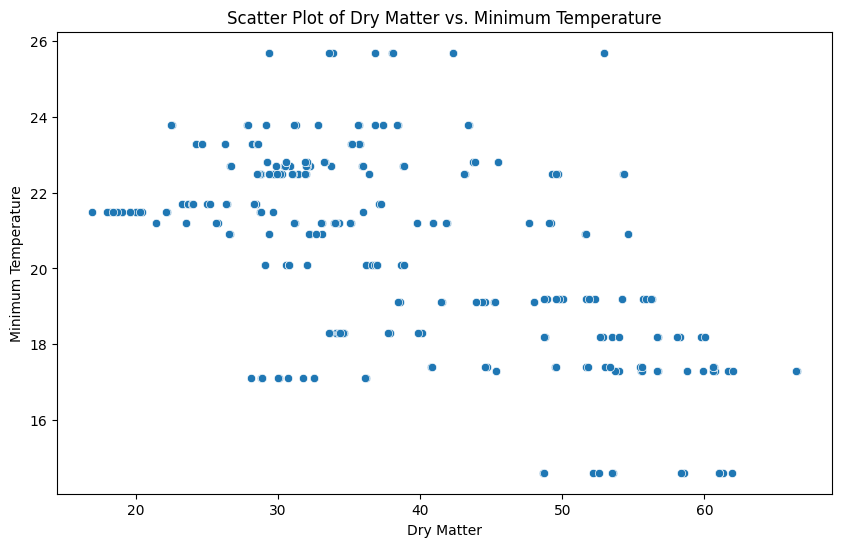

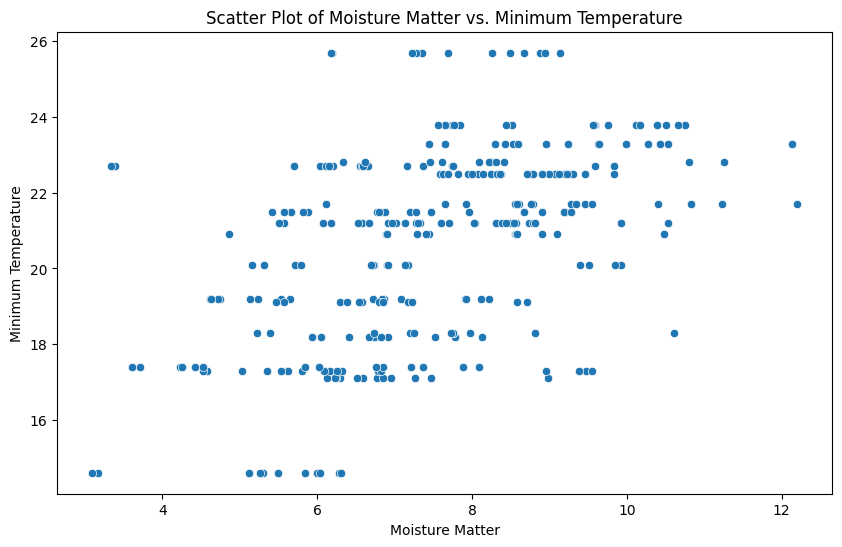

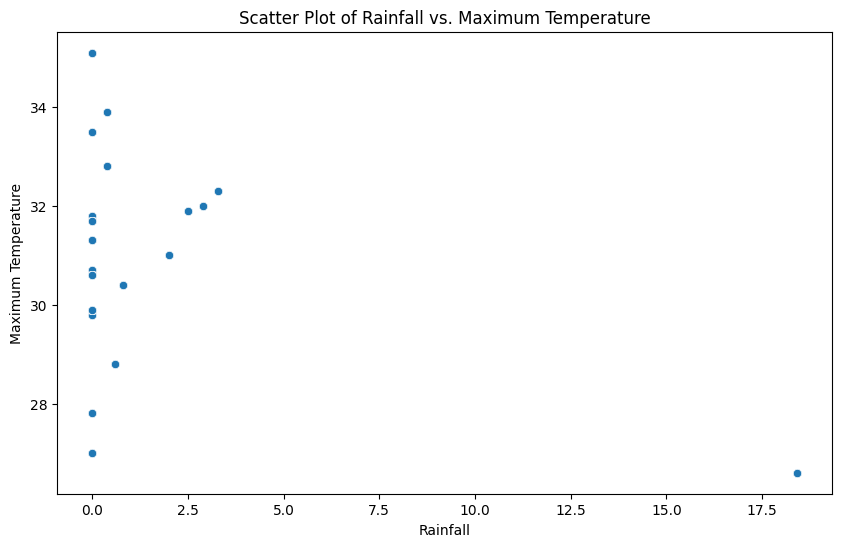

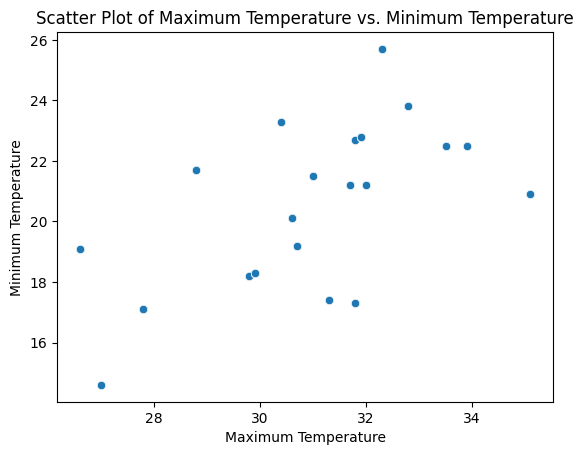

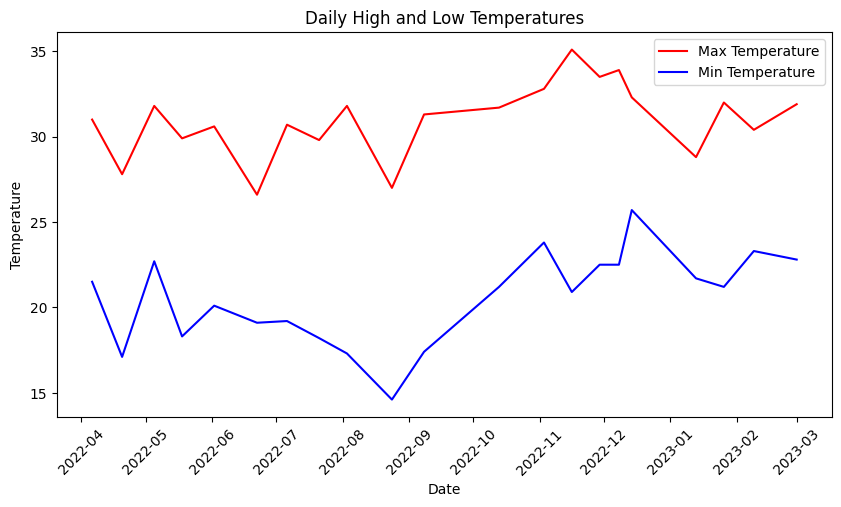

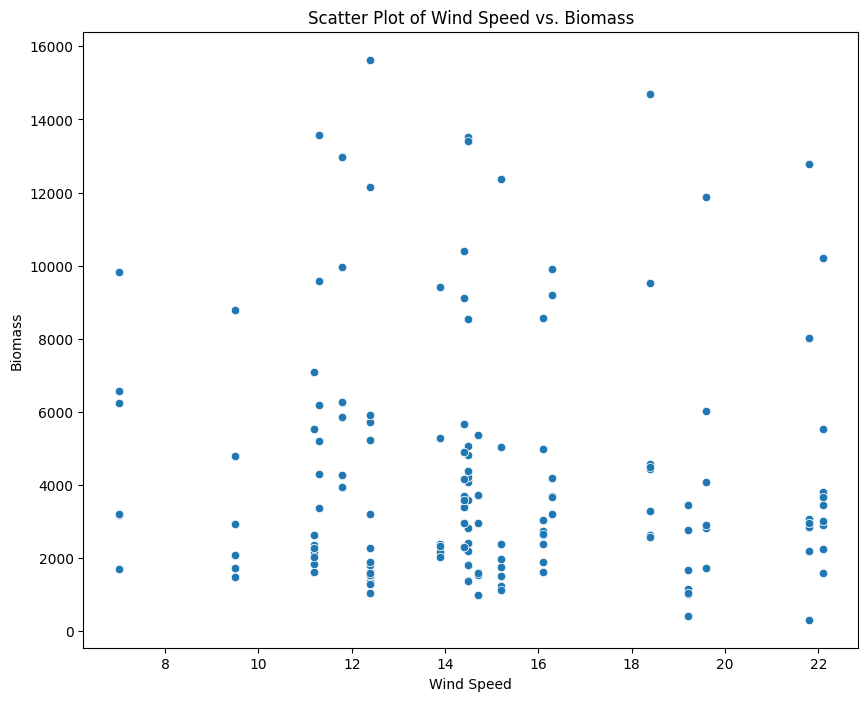

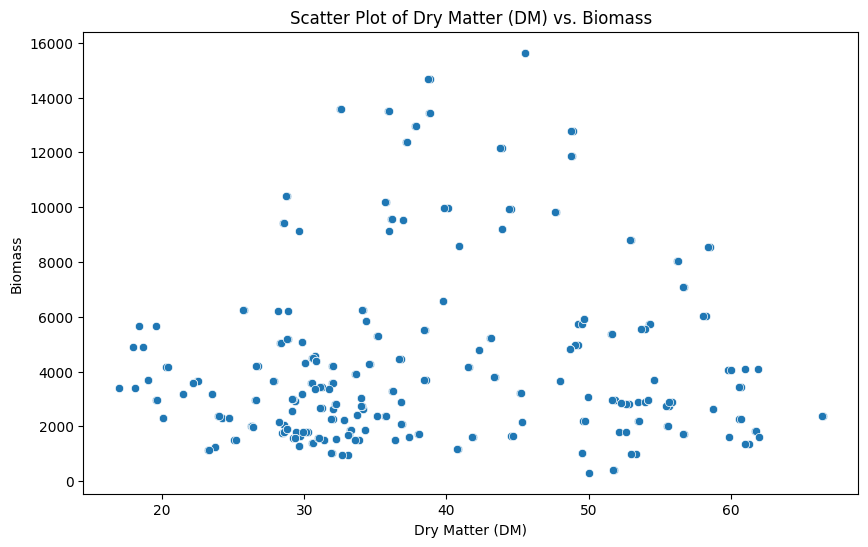

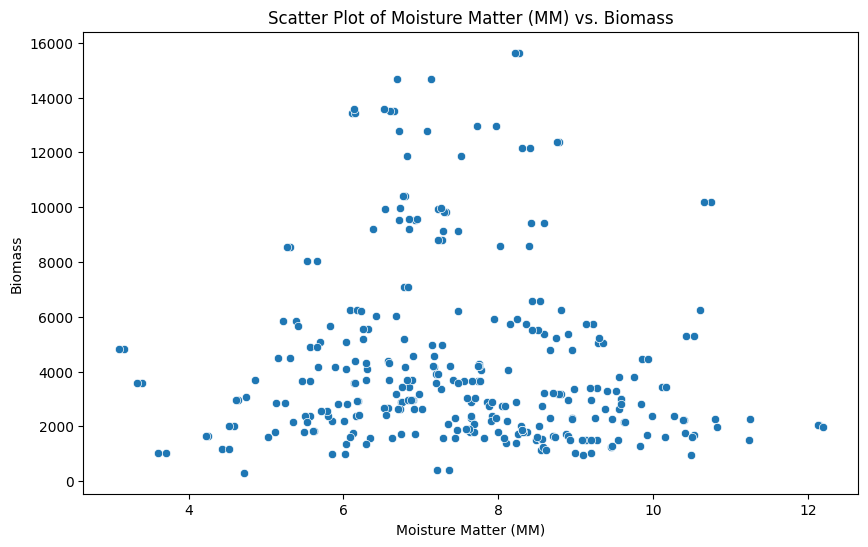

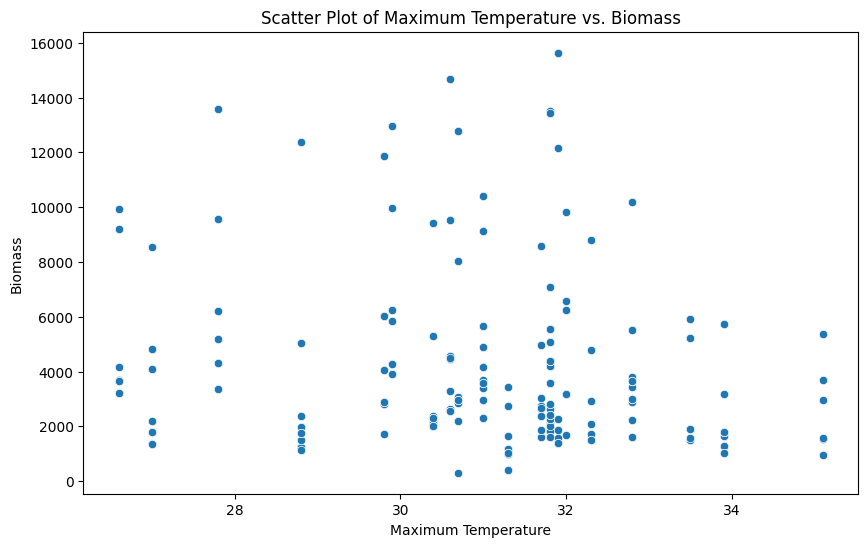

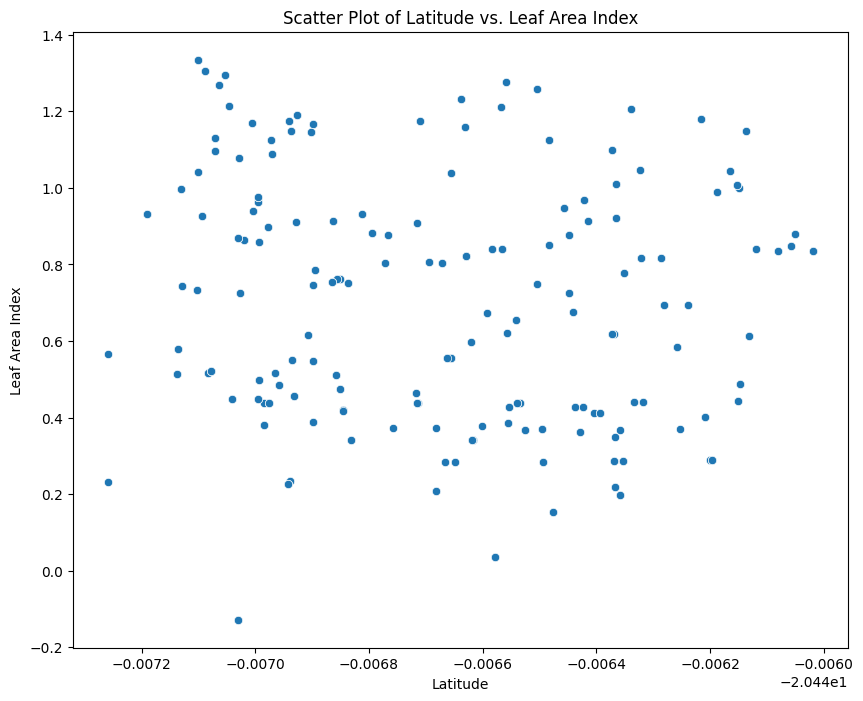

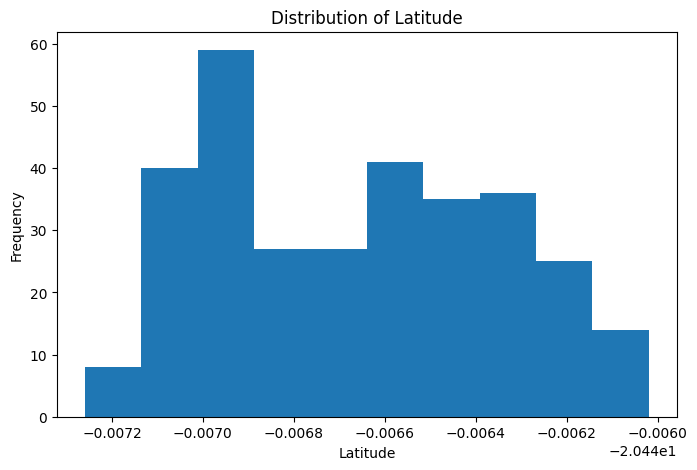

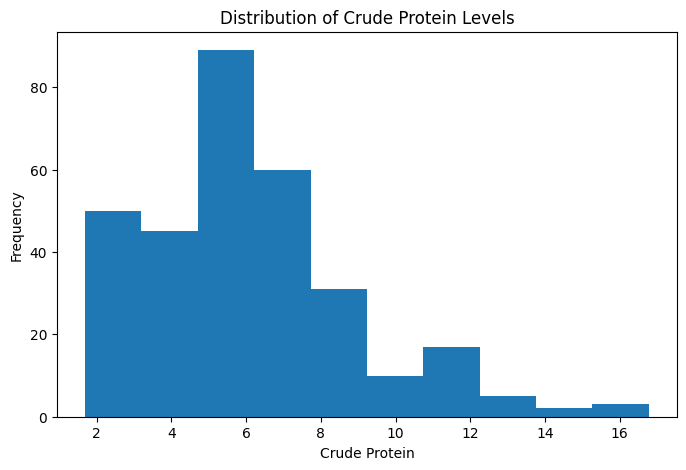

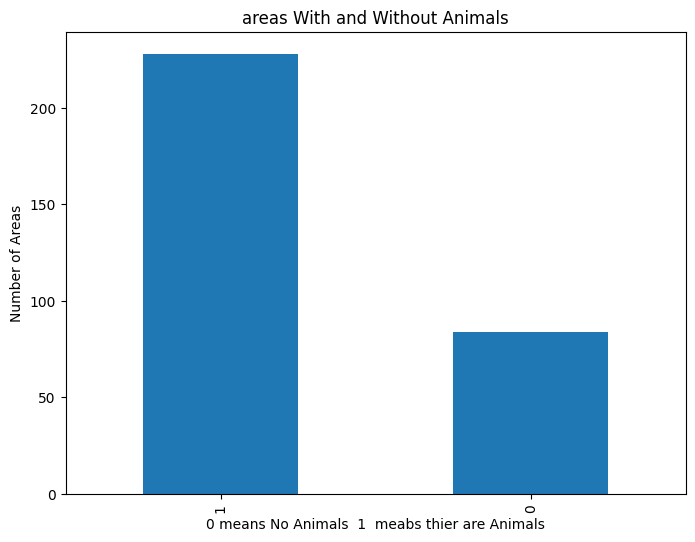

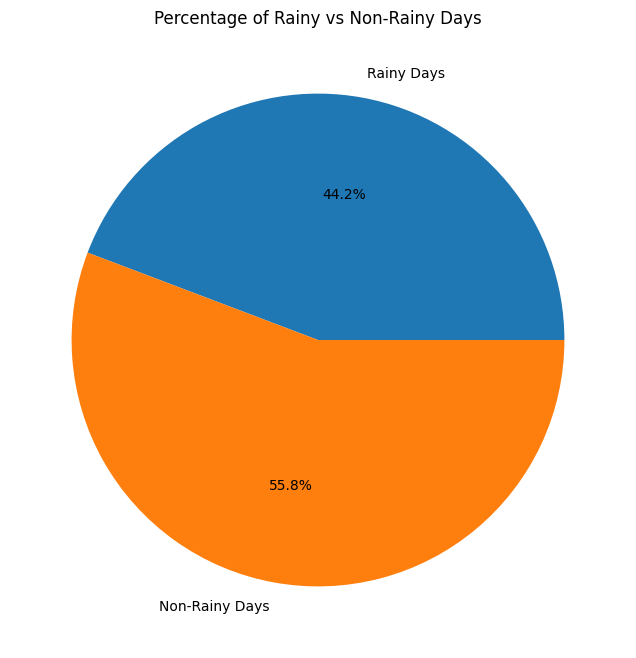

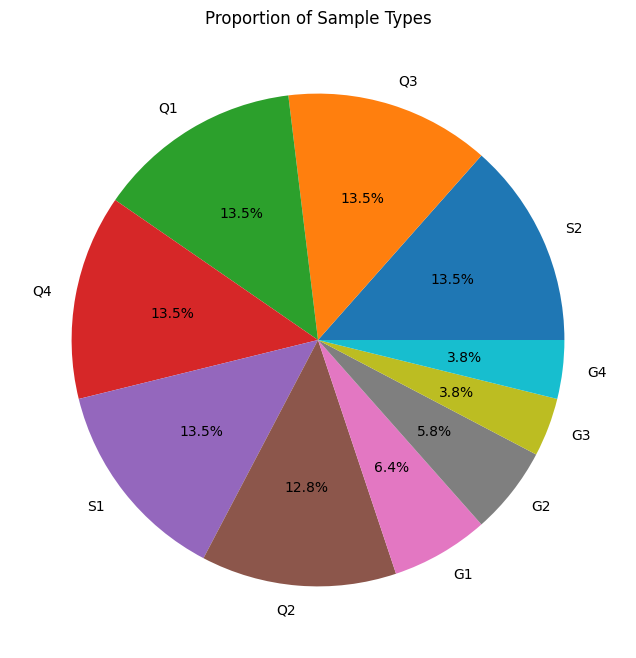

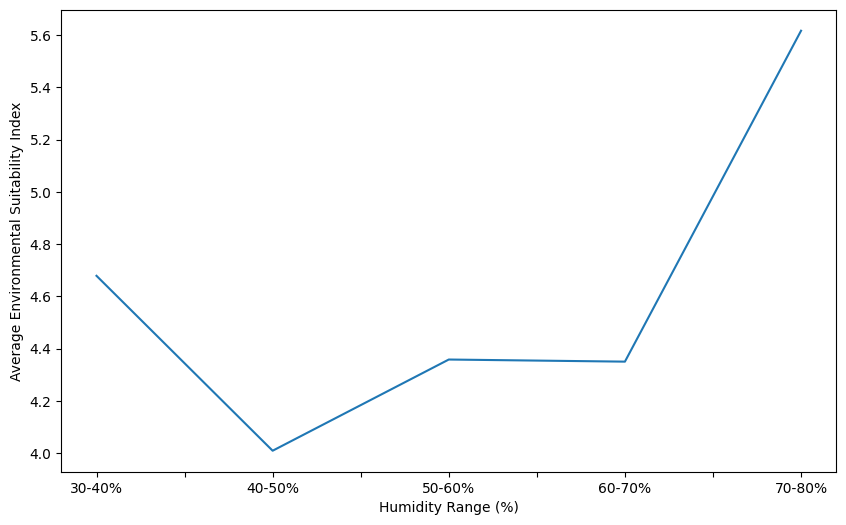

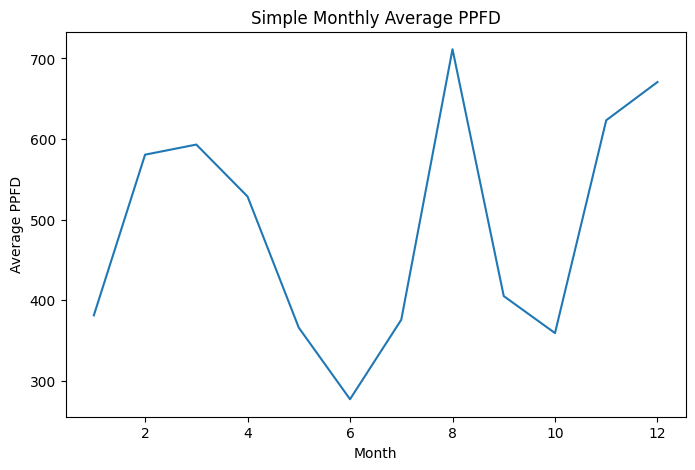

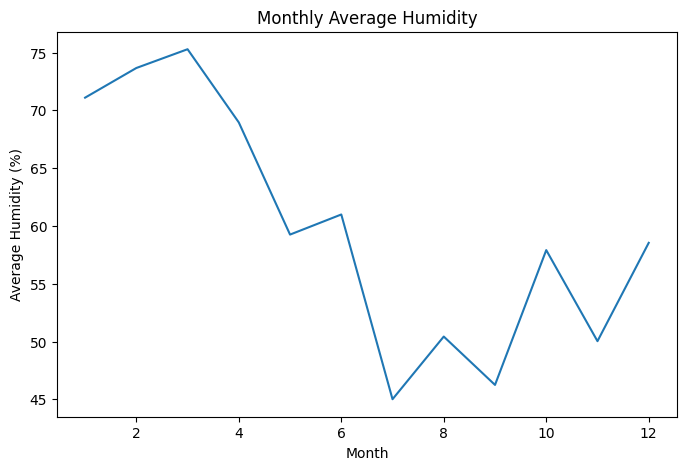

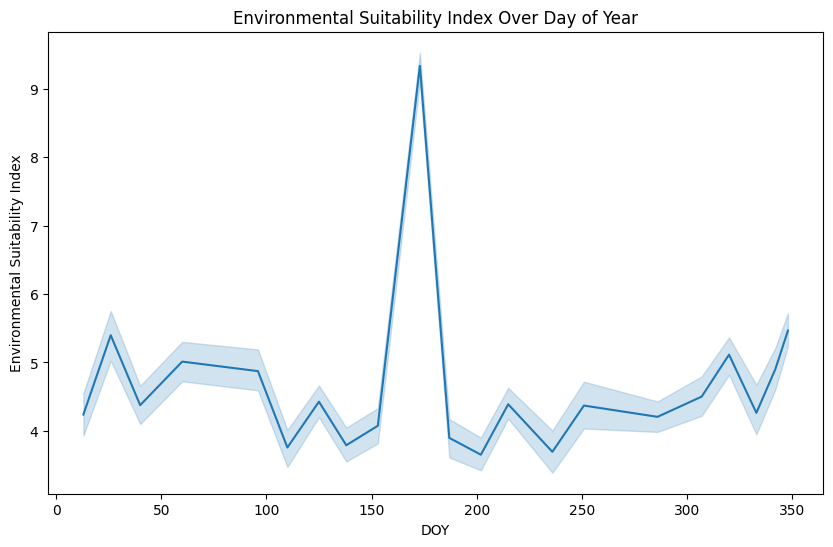

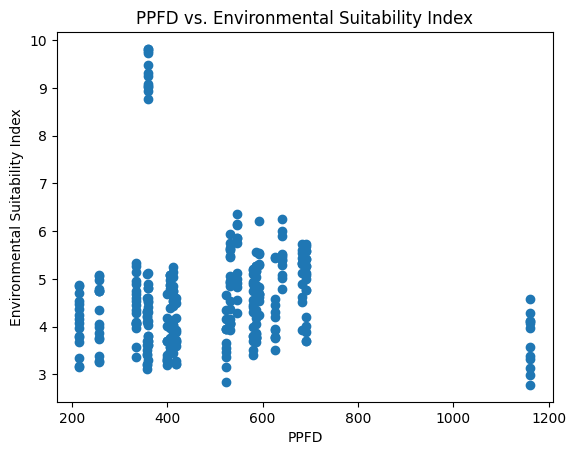

Animals,0,1
Sample_type,,
G1,0,20
G2,0,18
G3,0,12
G4,0,12
Q1,0,42
Q2,0,40
Q3,0,42
Q4,0,42
S1,42,0


In [14]:
# visulisations : 
df_copy = df.copy()



# from the shown histogram , relations figured:
    # Animals : Animals: More animals, less biomass.
    #ADF: More fiber, more biomass.
    #Latitude: Higher latitudes, less biomass.
    #Crude Protein: More protein, less biomass.
    #Water Index (NDWI): More water, more biomass.



# HISTO : 
# as my target is the biomass i will start by understanding its valeus frequency
sns.histplot(df_copy['Biomass'])
plt.title('Distribution of Biomass')
plt.xlabel('Biomass')
plt.ylabel('Frequency')
plt.show()
# this showing us that the data of the biomass are skewed to the right, and that most observatiosn where having between 1000 - 7000 value. 
# when the biomass is high , our observatiosn frequency where decreasing.  


# then i will start understanding the relations between the biomass and other relevent featurs , the seleciton of the featus is based on " what is the column about " . 
features = ['Biomass', 'Lat',  'DM', 'MM', 'LAI', 'TEMP_MAX', 'TEMP_MIN', 'Rainfall', 'WIND_SPD']
correlation = df_copy[features].corr()

plt.figure(figsize=(12, 10))
sns.heatmap(correlation, annot=True, fmt=".2f", cmap="coolwarm", cbar=True)
#1:matrix , 2:numbers included ,3:value formatting ,4:colorpallte, 5:ColorBar inlcuded.
plt.title("Correlation Heatmap of Biomass and  choosen Features")
plt.show()

#Ingshts: 
#max temp and rainfall : -0.4 --> High temp low rain. 
#lat and biomass : -0.49 --> higher Lat  ( move to poles ) is Lower Biomass , meaning that biomass is higher in خط الاستواء  
#DM and Mintemp : -0.56  --> String negative : when it dry more , min temp is lower -> the temp is higher 
#MM and tempMin : 0.5 --> most moituer higher minTemp .
#rainsfall and maxtemp : -0.4 --> lower rainfall  records when the temp is high 
#max temp with min temp : 0.56 --> when the maxTemp in a day is High ,the MinTmep in that day is high also, DO CHART TO UNDERSTAND THE CONSISTANCY IN EAHC DAY TEMP !

#lower:
#biomass and rain | max and min temp | wind : NO LINEAR RELATION BETWEEN THEM 
#biomass  has the strondest relation between the Lat and LAI . 
# DO OTHER CHARTS BETWEEN THEM TO MORE UNDERSTAND THE 




#CHARTS AFTER UNDERSTANDINT THE HEATMAP RELASTIONS :
#SCATTERS : 

# Plotting Biomass vs. Latitude
plt.figure(figsize=(10, 8))
sns.scatterplot(x=df_copy['Lat'], y=df_copy['Biomass'])
plt.title('Scatter Plot of Biomass vs. Latitude')
plt.xlabel('Latitude')
plt.ylabel('Biomass')
plt.show()

#biomass and LAI
plt.figure(figsize=(10, 8))
sns.scatterplot(x=df_copy['LAI'], y=df_copy['Biomass'])
plt.title('Scatter Plot of Biomass vs. Leaf Area Index')
plt.xlabel('Leaf Area Index')
plt.ylabel('Biomass')
plt.show()

#insght:
#we see no clear relation between them ( no clear trend ) 


# Rainfall vs Biomass
plt.figure(figsize=(8, 6))
sns.scatterplot(x='Rainfall', y='Biomass', data=df_copy)
plt.title('Rainfall vs Biomass')
plt.xlabel('Rainfall (mm)')
plt.ylabel('Biomass')
plt.show()
#this shows that thier it is not ( when the biomass is higher the rain is higher ), most of the data is when thier is LOW record of rain. 
#also , when the biomass is so high , the rain where very low or modirate , also thier are outliers , where all of the rain data poitns are from 0 - 3 , but htier are 5 points recorded that rain where almost 18.  
# DO A BOXPLOT !!!!

#Boxplot rainfuall
plt.figure(figsize=(8, 6))
sns.boxplot(df_copy['Rainfall'])
plt.title('Boxplot of Rainfall')
plt.show()
#insghts:
#typycal numbers are close to 0 ,rare high rainfalls. 





#Maxtemp with rain
plt.figure(figsize=(10, 6))
sns.scatterplot(x=df_copy['TEMP_MAX'], y=df_copy['Rainfall'])
plt.title('Scatter Plot of Max Temperature vs. Rainfall')
plt.xlabel('Maximum Temperature')
plt.ylabel('Rainfall')
plt.show()
#no relation 



plt.figure(figsize=(10, 6))
sns.scatterplot(x=df_copy['DM'], y=df_copy['TEMP_MIN'])
plt.title('Scatter Plot of Dry Matter vs. Minimum Temperature')
plt.xlabel('Dry Matter')
plt.ylabel('Minimum Temperature')
plt.show()
# No relation.

plt.figure(figsize=(10, 6))
sns.scatterplot(x=df_copy['MM'], y=df_copy['TEMP_MIN'])
plt.title('Scatter Plot of Moisture Matter vs. Minimum Temperature')
plt.xlabel('Moisture Matter')
plt.ylabel('Minimum Temperature')
plt.show()
#no relation 


plt.figure(figsize=(10, 6))
sns.scatterplot(x=df_copy['Rainfall'], y=df_copy['TEMP_MAX'])
plt.title('Scatter Plot of Rainfall vs. Maximum Temperature')
plt.xlabel('Rainfall')
plt.ylabel('Maximum Temperature')
plt.show()
#no relation 


sns.scatterplot(x=df_copy['TEMP_MAX'], y=df_copy['TEMP_MIN'])
plt.title('Scatter Plot of Maximum Temperature vs. Minimum Temperature')
plt.xlabel('Maximum Temperature')
plt.ylabel('Minimum Temperature')
plt.show()
# strong and clear relatio , when the temp goes high in a day , its drop nown in stable . 
#DO LINE CHART.

df_copy['Date'] = pd.to_datetime(df_copy['Date'])# becouse dates where ot able to be sotred becouse of thier format.
df_copy.sort_values('Date', ascending=False, inplace=True)# just sorting 
plt.figure(figsize=(10, 5))
plt.plot(df_copy['Date'], df_copy['TEMP_MAX'], label='Max Temperature', color='red')
plt.plot(df_copy['Date'], df_copy['TEMP_MIN'], label='Min Temperature', color='blue')
plt.title('Daily High and Low Temperatures')
plt.xlabel('Date')
plt.ylabel('Temperature')
plt.xticks(rotation=45)
plt.legend()
plt.show()
#insghts:
#sharp ups and downs in both, The gap between the highest and lowest temperatures each day generally stays consistent, 








#from here, i wanted to plot the results where thier where no rwlally stong relations 
# wind vs Biomass ( geographical location  ) 
plt.figure(figsize=(10, 8))
sns.scatterplot(x=df_copy['WIND_SPD'], y=df_copy['Biomass'])
plt.title('Scatter Plot of Wind Speed vs. Biomass')
plt.xlabel('Wind Speed')
plt.ylabel('Biomass')
plt.show()
#No trend refare to a strong relation


# Dm vs Biomass ( dry matter ) 
plt.figure(figsize=(10, 6))
sns.scatterplot(x=df_copy['DM'], y=df_copy['Biomass'])
plt.title('Scatter Plot of Dry Matter (DM) vs. Biomass')
plt.xlabel('Dry Matter (DM)')
plt.ylabel('Biomass')
plt.show()

# MM vs Biomass ( mositure matter ) 
plt.figure(figsize=(10, 6))
sns.scatterplot(x=df_copy['MM'], y=df_copy['Biomass'])
plt.title('Scatter Plot of Moisture Matter (MM) vs. Biomass')
plt.xlabel('Moisture Matter (MM)')
plt.ylabel('Biomass')
plt.show()


# Maxtemp  vs Biomass ( leaf cover area ) 
plt.figure(figsize=(10, 6))
sns.scatterplot(x=df_copy['TEMP_MAX'], y=df_copy['Biomass'])
plt.title('Scatter Plot of Maximum Temperature vs. Biomass')
plt.xlabel('Maximum Temperature')
plt.ylabel('Biomass')
plt.show()


#lat with the LAI:
plt.figure(figsize=(10, 8))
sns.scatterplot(x=df_copy['Lat'], y=df_copy['LAI'])
plt.title('Scatter Plot of Latitude vs. Leaf Area Index')
plt.xlabel('Latitude')
plt.ylabel('Leaf Area Index')
plt.show()

#NO RELATIONs !!!!!


# Plot about Latitude Distribution   # خطوط العرض
plt.figure(figsize=(8, 5))
plt.hist(df_copy['Lat'])
plt.title('Distribution of Latitude')
plt.xlabel('Latitude')  
plt.ylabel('Frequency')
plt.show()
#This tells us that alot of our biomass samples are taken around specific latitude ranges.


# Plot Crude Protein Distribution
plt.figure(figsize=(8, 5))
plt.hist(df_copy['CP'])
plt.title('Distribution of Crude Protein Levels')
plt.xlabel('Crude Protein')
plt.ylabel('Frequency')
plt.show()
#this tells that thier are many samples the protivne is from 4-8  in it ,and rare samples have that mich high level of protine in it.



#COLUMN :
animal_counts = df_copy['Animals'].value_counts()

plt.figure(figsize=(8, 6))
animal_counts.plot(kind='bar')
plt.title('areas With and Without Animals')
plt.xlabel('0 means No Animals  1  meabs thier are Animals')
plt.ylabel('Number of Areas')#frequency 
plt.show()
#from this plt we see that more than double of areas have animals comared to areas dont have .




# Count rainy and non-rainy days
sizes = [
    (df_copy['Rainfall'] != 0).sum(),  # Count therainy days , here the boolean is returning T F so the .sum () will count the T as 1s
    (df_copy['Rainfall'] == 0).sum()  # Count didnot-rained days
]
labels = ['Rainy Days', 'Non-Rainy Days']
plt.figure(figsize=(8, 8))
plt.pie(sizes, labels=labels, autopct='%1.1f%%')
plt.title('Percentage of Rainy vs Non-Rainy Days')
plt.show()
# this tells that Rainfall and dry days are nearly balanced, indicating a consistent weather pattern.

# Sample_type
sample_counts = df_copy['Sample_type'].value_counts()
plt.figure(figsize=(8, 8))
plt.pie(sample_counts, labels=sample_counts.index, autopct='%1.1f%%') #index enabling me reaching the names of carigories becouse i am in series . 
plt.title('Proportion of Sample Types')
plt.show()
#thier are 5 types of samples that most of the date are from them 




humidity_ranges = pd.cut(df['HUM_REL'], bins=[30, 40, 50, 60, 70, 80], labels=['30-40%', '40-50%', '50-60%', '60-70%', '70-80%'])

# Calculate the average ESI for each humidity range
avg_esi = df.groupby(humidity_ranges)['Environmental Suitability Index'].mean()
plt.figure(figsize=(10, 6))
avg_esi.plot(kind='line')
plt.xlabel('Humidity Range (%)')
plt.ylabel('Average Environmental Suitability Index')
plt.show()
#Insght: THIS TELLS THAT HIGHER HUMIDITY WILL LEAD TO HIGHER ASI


df['Date'] = pd.to_datetime(df['Date'])
df['Month'] = df['Date'].dt.month
monthly_ppfd_avg = df.groupby('Month')['PPFD'].mean()
plt.figure(figsize=(8, 5))
plt.plot(monthly_ppfd_avg)
plt.title('Simple Monthly Average PPFD')
plt.xlabel('Month')
plt.ylabel('Average PPFD')
plt.show()


# ENVIROMANTAL SUITABILITY INDIX IS : TELLING HM THE PLEACE IS SUITABLE FOR ACTIVITIES.



df['Date'] = pd.to_datetime(df['Date'])
df['Month'] = df['Date'].dt.month
avg_humidity_by_month = df.groupby('Month')['HUM_REL'].mean()
plt.figure(figsize=(8, 5))
plt.plot(avg_humidity_by_month)
plt.title('Monthly Average Humidity')
plt.xlabel('Month')
plt.ylabel('Average Humidity (%)')
plt.show()


#include for multi column 


#Environmental Suitability Index over the Day of Year
plt.figure(figsize=(10, 6))
sns.lineplot(x='DOY', y='Environmental Suitability Index', data=df_copy)
plt.title('Environmental Suitability Index Over Day of Year')
plt.xlabel('DOY')
plt.ylabel('Environmental Suitability Index')
plt.show()
#insght: the changes ups and downs over the year shows that thier are some days better than other for activities , the high indix in the middle of the year shows the best time for going activities.


plt.scatter(df_copy['PPFD'], df_copy['Environmental Suitability Index'])
plt.title('PPFD vs. Environmental Suitability Index')
plt.xlabel('PPFD')
plt.ylabel('Environmental Suitability Index')
plt.show()
#insght : higher sun lights and eergy lead to higher ESI


contingencyTable = pd.crosstab(
    df_copy['Sample_type'],
    df_copy['Animals'],
)
   
contingencyTable
#insght: no anlimals in S1 and S2 types. Where all other types have anlimals


